# M04 — Física directa y controles de prismas inducidos

**Pregunta:** ¿Cuándo coincide el prisma inducido con el oráculo independiente y cuándo falla la TMI lineal?

**Nivel 3 · Prerrequisitos: notebook de fundamentos; lectura: 25 minutos.**


## Objetivos

Ejecute el operador directo de prismas inducidos sobre una solicitud sintética explícita de una celda. Compare componentes con la función física independiente de prismas de Choclo y distinga TMI lineal de anomalía exacta de magnitud. No es inversión de susceptibilidad ni clasificador de remanencia.


## Preparación

Use el entorno pipeline Python 3.12 ya revisado. Este notebook no instala nada.
Importe el código del repositorio y confirme su archivo fuente.

In [1]:
import sys
from pathlib import Path
import numpy as np

root = Path.cwd().parents[2]
sys.path.insert(0, str(root / "data-pipeline"))
import magnetic_forward

# Reutilice el control físico sintético fijado del producto.
import choclo
from choclo.constants import VACUUM_MAGNETIC_PERMEABILITY as mu0

# Entrada fija de simulación con un prisma; la fuente es modelada, no observada.
request = {
    "schema": "magnetic-prism-forward-request-1",
    "engine": magnetic_forward.ENGINE,
    "frame": dict(magnetic_forward.FRAME),
    "mesh": {
        "origin_m": np.array([-50.0, -40.0, -120.0]),
        "hx_m": np.array([100.0]),
        "hy_m": np.array([80.0]),
        "hz_m": np.array([120.0]),
        "active": np.array([True]),
    },
    "receivers_m": np.array([[0.0, 0.0, 100.0], [170.0, 30.0, 120.0], [-100.0, 160.0, 240.0]]),
    "susceptibility_si": np.array([0.03]),
    "inducing_field": {"amplitude_nt": 50000.0, "inclination_deg": 60.0, "declination_deg": 12.0},
}
prism_bounds = (-50.0, 50.0, -40.0, 40.0, -120.0, 0.0)
print(magnetic_forward.ENGINE)


simpeg-0.25.2-geoana-0.8.1-f64-induced-ram


## Datos

Ejecute el operador directo de prismas inducidos sobre una solicitud sintética explícita de una celda. Compare componentes con la función física independiente de prismas de Choclo y distinga TMI lineal de anomalía exacta de magnitud. No es inversión de susceptibilidad ni clasificador de remanencia.

**Archivos:** `data-pipeline/magnetic_forward.py`, `docs/design/features/m04-induced-prism/algorithms.md`, `docs/design/features/m04-induced-prism/validation.md`.

## Método

Para I positiva hacia abajo y D horario desde norte, f=(cos I sin D, cos I cos D, −sin I) ENU; B₀=Ff. La magnetización inducida uniforme es M=χ·10⁻⁹B₀/μ₀ A m⁻¹. b secundario da TMI lineal f·b; la anomalía exacta es |B₀+b|−F. Supuestos: campo uniforme, susceptibilidad escalar, sin autodesmagnetización ni remanencia.

Para inclinación I y declinación D, f=(cos I sin D, cos I cos D, −sin I) en este/norte/arriba; Ff es el campo inductor en nT. La susceptibilidad escalar χ es adimensional y la magnetización inducida ideal es M=χ·10⁻⁹Ff/μ₀ A m⁻¹. El campo secundario vectorial integra μ₀/(4π)[3(M·R)R/|R|⁵−M/|R|³] sobre volumen de cada prisma y convierte tesla a nT. TMI lineal es f·b. La anomalía de magnitud exacta es |Ff+b|−F, no |b|. Solo TMI lineal tiene el Jacobiano devuelto respecto de χ. Para |b|≪F, anomalías exacta y lineal se acercan; su diferencia diagnostica el error de aproximación.

Supuestos: campo fuente uniforme, χ escalar por celda, sin remanencia ni autodesmagnetización. El procesador no infiere estos supuestos ni clasifica un levantamiento real. La transecta este agregada es un experimento determinista de modelado basado en el fixture de un prisma del producto. Sus componentes se comparan con la integral física independiente de Choclo; la curva exacta menos lineal cuantifica la aproximación de proyección en este caso. Una diferencia pequeña con el oráculo valida solo ese cálculo controlado, no inversión, validez de fuente de campo ni aceptación del host.

Ejecute el método del producto sobre el control declarado.

In [2]:
# Compare las componentes de producción con la función física independiente de prismas magnéticos de Choclo.
result = magnetic_forward.forward_magnetic(request)
f = result["inducing_field"]["direction_enu"]
F = request["inducing_field"]["amplitude_nt"]
M = request["susceptibility_si"][0] * F * 1e-9 * f / mu0
oracle = np.array([choclo.prism.magnetic_field(*r, *prism_bounds, *M) for r in request["receivers_m"]]) * 1e9
max_error = float(np.max(np.abs(result["field_components_nt"] - oracle)))
print(
    {
        "componentes_nT": result["field_components_nt"].tolist(),
        "TMI_lineal_nT": result["linear_tmi_nt"].tolist(),
        "anomalia_magnitud_nT": result["exact_magnitude_anomaly_nt"].tolist(),
        "error_componente_maximo_nT": max_error,
        "aceptado": result["linearization"]["full_method_accepted"],
    }
)


{'componentes_nT': [[-3.083885319869999, -15.196751023702873, -52.600520412756026], [-8.37992389035097, -5.113501807685271, -1.3490249144903828], [0.9113899363806939, -3.1976523174842035, -1.2633513449759988]], 'TMI_lineal_nT': [37.800466247765534, -2.203731988464365, -0.3750493011759808], 'anomalia_magnitud_nT': [37.81623823240539, -2.2027986027475563, -0.3749241901716595], 'error_componente_maximo_nT': 1.8385293287792592e-13, 'aceptado': False}


Control adversarial/negativo: aísle un supuesto o incumpla una restricción física declarada.

In [3]:
from copy import deepcopy

changed = deepcopy(request)
changed["inducing_field"]["declination_deg"] = 42.0
# Cambie solo un supuesto declarado del campo; esto no clasifica datos de campo.
alternative = magnetic_forward.forward_magnetic(changed)
delta = float(np.max(np.abs(alternative["field_components_nt"] - result["field_components_nt"])))
print({"max_component_change_nT": delta})
assert delta > 0


{'max_component_change_nT': 6.84110757451481}


## Estado del arte

SimPEG/Geoana es el marco de producción ([Cockett et al., 2015](https://doi.org/10.1016/j.cageo.2015.09.015)); el control del producto lo compara con un cálculo independiente de prisma. Cambiar el campo prueba sensibilidad, no identifica el campo real. Magnitud exacta y TMI lineal difieren; el Jacobiano devuelto corresponde solo a TMI lineal.
Esta transecta sintética determinista usa el operador de producción y un oráculo físico separado. El panel exacta menos lineal es un diagnóstico de aproximación en nT, no un umbral universal ni una anomalía medida.


In [4]:
from copy import deepcopy
import matplotlib.pyplot as plt

# Recalcular transecta física este con método del producto y oráculo independiente de Choclo.
transecta = deepcopy(request)
este = np.linspace(-500.0, 500.0, 81)
transecta["receivers_m"] = np.column_stack([este, np.zeros_like(este), np.full_like(este, 100.0)])
p = magnetic_forward.forward_magnetic(transecta)
f = p["inducing_field"]["direction_enu"]
F = transecta["inducing_field"]["amplitude_nt"]
M = transecta["susceptibility_si"][0] * F * 1e-9 * f / mu0
componentes_oraculo = (
    np.array([choclo.prism.magnetic_field(*r, *prism_bounds, *M) for r in transecta["receivers_m"]]) * 1e9
)
err = float(np.max(np.abs(p["field_components_nt"] - componentes_oraculo)))
lineal = p["linear_tmi_nt"]
exacta = p["exact_magnitude_anomaly_nt"]


### Comparar anomalías exacta y linealizada

Los cálculos del producto y del oráculo independiente establecen primero el acuerdo de componentes. Esta figura contrasta la proyección de primer orden con la magnitud exacta del campo total en la transecta de receptores.

{'error_maximo_componentes_vs_oraculo_nT': 2.4724666758402236e-13, 'diferencia_maxima_exacta_lineal_nT': 0.01622152471291116, 'maxima_razon_secundario_inductor': 0.001096770958411151, 'metodo_completo_aceptado': False}


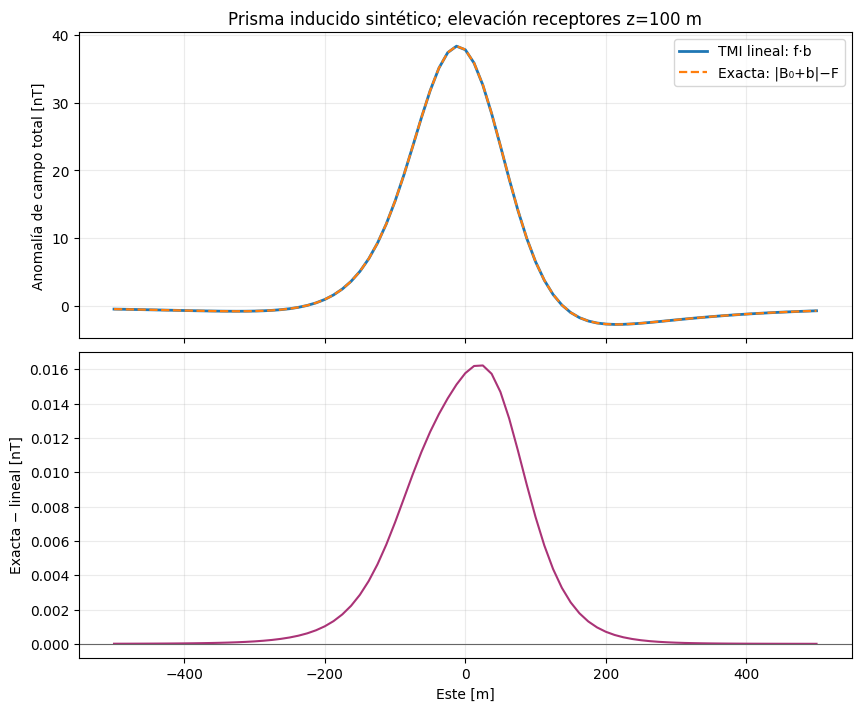

In [5]:
# Comparar anomalías exacta y linealizada.
fig, (ax, bx) = plt.subplots(2, 1, figsize=(8.5, 7), sharex=True, constrained_layout=True)
ax.plot(este, lineal, label="TMI lineal: f·b", lw=2)
ax.plot(este, exacta, "--", label="Exacta: |B₀+b|−F", lw=1.6)
ax.set(ylabel="Anomalía de campo total [nT]", title="Prisma inducido sintético; elevación receptores z=100 m")
ax.legend()
ax.grid(alpha=0.25)
bx.plot(este, exacta - lineal, color="#aa3377")
bx.axhline(0, color=".4", lw=0.8)
bx.set(xlabel="Este [m]", ylabel="Exacta − lineal [nT]")
bx.grid(alpha=0.25)
print(
    {
        "error_maximo_componentes_vs_oraculo_nT": err,
        "diferencia_maxima_exacta_lineal_nT": p["linearization"]["maximum_abs_difference_nt"],
        "maxima_razon_secundario_inductor": float(np.max(p["linearization"]["secondary_to_background_ratio"])),
        "metodo_completo_aceptado": p["linearization"]["full_method_accepted"],
    }
)
plt.show()


### Inspeccionar la respuesta del prisma de referencia

Las componentes graficadas muestran el campo ENU con signo generado por el prisma inducido declarado en sus receptores. La polaridad depende de la convención ENU del repositorio y de la dirección del campo inductor. Es una respuesta directa de un cuerpo ideal; no estima susceptibilidad, remanencia ni la existencia de una fuente equivalente en terreno.


In [6]:
# Duplicar susceptibilidad aísla la respuesta de amplitud directa.
changed_chi = deepcopy(request)
changed_chi["susceptibility_si"] = request["susceptibility_si"] * 2
chi_result = magnetic_forward.forward_magnetic(changed_chi)
print(float(np.max(np.abs(chi_result["field_components_nt"] - result["field_components_nt"]))))


52.600520412756026


Cambiar solo inclinación prueba la convención vertical declarada.

In [7]:
# Cambiar solo inclinación prueba la convención vertical declarada.
changed_inc = deepcopy(request)
changed_inc["inducing_field"]["inclination_deg"] = 45.0
inc_result = magnetic_forward.forward_magnetic(changed_inc)
print(float(np.max(np.abs(inc_result["field_components_nt"] - result["field_components_nt"]))))


9.652375340721662


La transecta anterior compara observables lineales y exactos para una susceptibilidad declarada. Este segundo cálculo cambia la susceptibilidad en un rango de tres factores y mantiene geometría del prisma, campo y receptores fijos. Prueba la escala de amplitud y la corrección no lineal de magnitud bajo la misma física directa, distinguiendo un cambio de forma de un simple cambio escalar de amplitud.

Recalcule la transecta este con tres escalas de susceptibilidad.

{0.5: 0.004056702754485997, 1.0: 0.01622152471291116, 2.0: 0.06484383398431248}


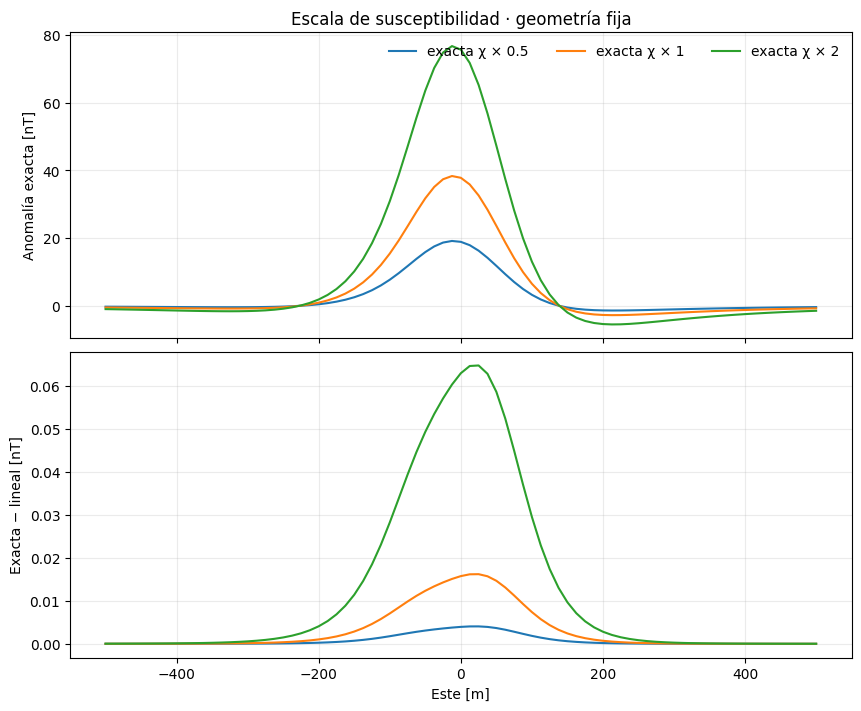

In [8]:
# Vuelva a ejecutar el método directo de producción cambiando solo la susceptibilidad.
import matplotlib.pyplot as plt

scales = (0.5, 1.0, 2.0)
profiles = {}
for scale in scales:
    case = deepcopy(transecta)
    case["susceptibility_si"] = request["susceptibility_si"] * scale
    profiles[scale] = magnetic_forward.forward_magnetic(case)
fig, (ax, bx) = plt.subplots(2, 1, figsize=(8.5, 7), sharex=True, constrained_layout=True)
for scale, case_result in profiles.items():
    ax.plot(este, case_result["exact_magnitude_anomaly_nt"], label=f"exacta χ × {scale:g}")
    bx.plot(este, case_result["exact_magnitude_anomaly_nt"] - case_result["linear_tmi_nt"], label=f"χ × {scale:g}")
ax.set(ylabel="Anomalía exacta [nT]", title="Escala de susceptibilidad · geometría fija")
bx.set(xlabel="Este [m]", ylabel="Exacta − lineal [nT]")
ax.legend(frameon=False, ncol=3)
for panel in (ax, bx):
    panel.grid(alpha=0.25)
print(
    {
        scale: float(np.max(np.abs(v["exact_magnitude_anomaly_nt"] - v["linear_tmi_nt"])))
        for scale, v in profiles.items()
    }
)
plt.show()


El panel superior muestra la anomalía de magnitud exacta al cambiar la susceptibilidad; el inferior aísla su diferencia con la proyección lineal. Como geometría, campo inductor y receptores permanecen fijos, las diferencias provienen del momento inducido y de la norma vectorial exacta. La respuesta lineal debe escalar proporcionalmente con la susceptibilidad, mientras la corrección no lineal crece cuando el campo secundario deja de ser despreciable frente al campo de fondo. Esta sensibilidad controlada no infiere una distribución de susceptibilidad de terreno.

## Resultados

Use las tolerancias independientes fijadas, no los valores redondeados. Cambiar la declinación debe cambiar las componentes. La discrepancia máxima de componentes frente a Choclo es 2.47×10⁻¹³ nT. La diferencia máxima entre TMI exacta y lineal es 0.0162215 nT, y la razón entre campo secundario e inductor es 0.00109677. La aceptación completa del método sigue en falso.

El operador M04 calcula el campo secundario ENU, la TMI lineal y el cambio exacto de magnitud para un prisma inducido. Choclo coteja las componentes de manera independiente. Esta concordancia valida un kernel directo acotado, no la recuperación de susceptibilidad, la remanencia ni la geología de campo.

### Inversión de susceptibilidad y control de campo inducido fallido

Ejecute las inversiones integrales 3D del producto sobre el levantamiento sembrado de diques inclinados con el campo inductor declarado. La cobertura reducida ajusta estaciones alternadas y evalúa las intercaladas; esta comprobación de interpolación deliberadamente favorable no es una prueba de campo espacialmente independiente. Luego ejecute la construcción con remanencia, cuya dirección de magnetización difiere del campo inductor uniforme supuesto. Su ajuste escalar de susceptibilidad es un **control negativo de modelo físico**, mientras la solución vectorial estima magnetización efectiva. Son nuevas ejecuciones del solver, no gráficos de casos precomputados del navegador.


In [9]:
# Invierta diques inducidos y ejecute el control negativo remanente.
from geology import registry
import potential

magnetic_case = next(case for case in registry() if case["id"] == "MAGNETIC_DYKE")
magnetic_inverse = potential.solve_case(magnetic_case, "coverage", {})
magnetic_shape = tuple(magnetic_inverse["grid"]["shape"])
magnetic_methods = magnetic_inverse["methods"]
for method_id, method in magnetic_methods.items():
    metrics = method["metrics"]
    print(method["name"], {
        "wrms_ajuste": metrics["wrms"],
        "wrms_reserva_intercalada": metrics.get("heldout_wrms"),
        "rmse_modelo_si": metrics["model_rmse"],
        "razon_modelo_inicial": metrics["baseline_ratio"],
        "evaluacion": method["evaluation"],
    })

remanence_case = next(case for case in registry() if case["id"] == "MAGNETIC_REMANENCE")
remanence_inverse = potential.solve_case(remanence_case, "coverage", {})
for method_id, method in remanence_inverse["methods"].items():
    metrics = method["metrics"]
    print("control de remanencia ·", method["name"], {
        "wrms_ajuste": metrics["wrms"],
        "wrms_reserva_intercalada": metrics.get("heldout_wrms"),
        "evaluacion": method["evaluation"],
        "error_direccion_grados": metrics.get("direction_error_deg"),
    })


Spatially regularized L2 {'wrms_ajuste': 1.0000000000000395, 'wrms_reserva_intercalada': 1.691955641240732, 'rmse_modelo_si': 0.010169835811351842, 'razon_modelo_inicial': 0.8677332890516457, 'evaluacion': {'status': 'unresolved', 'reason_codes': ['low-model-correlation']}}
Spatial L1/L2 IRLS {'wrms_ajuste': 0.9999999999999093, 'wrms_reserva_intercalada': 1.6686725183695816, 'rmse_modelo_si': 0.010182723198108689, 'razon_modelo_inicial': 0.8688328952503335, 'evaluacion': {'status': 'unresolved', 'reason_codes': ['low-model-correlation']}}
Vector magnetization {'wrms_ajuste': 0.9999999999998508, 'wrms_reserva_intercalada': 2.206407552591117, 'rmse_modelo_si': 0.010663700344632817, 'razon_modelo_inicial': 0.9098718942129508, 'evaluacion': {'status': 'unresolved', 'reason_codes': ['withheld-data-not-predicted', 'low-model-correlation']}}
control de remanencia · Spatially regularized L2 {'wrms_ajuste': 0.9999999999999987, 'wrms_reserva_intercalada': 1.614411844560472, 'evaluacion': {'statu

Lea por separado WRMS de datos predichos, RMSE del modelo, mejora frente al modelo cero y veredicto del método. Un WRMS cercano a uno en el ajuste no garantiza predicción retenida. La susceptibilidad escalar y la magnetización vectorial tienen parametrizaciones distintas; la norma del vector no es una estimación de susceptibilidad resuelta en profundidad. En el control remanente, el buen ajuste de un modelo vectorial flexible no valida el supuesto escalar solo inducido.


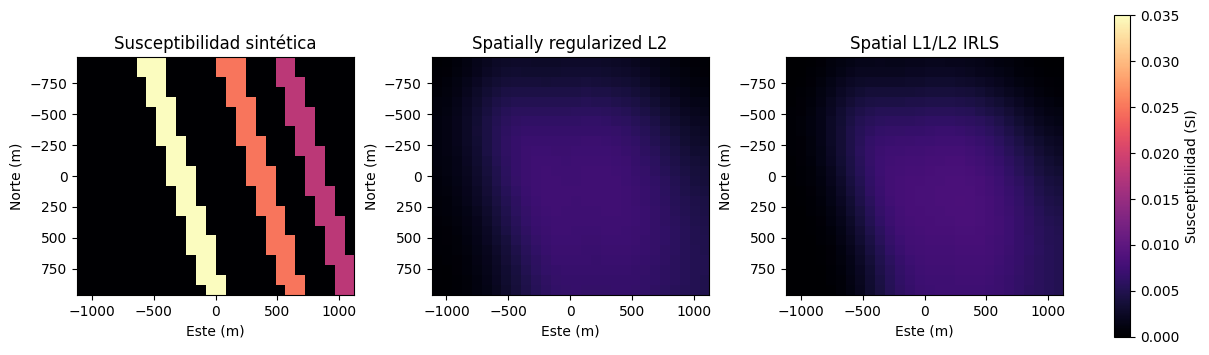

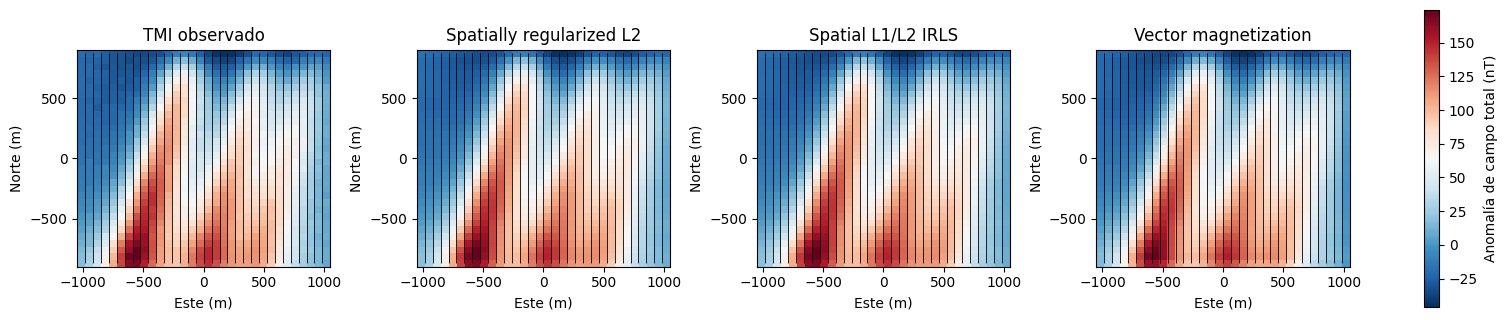

In [10]:
# Compare cortes de susceptibilidad y mapas TMI observados / predichos.
truth = np.asarray(magnetic_inverse["truth"]).reshape(magnetic_shape)
z_index = magnetic_shape[0] // 2
models = [("Susceptibilidad sintética", truth)] + [(magnetic_methods[key]["name"], np.asarray(magnetic_methods[key]["model"]).reshape(magnetic_shape)) for key in ("l2", "irls")]
limit = max(float(np.max(np.abs(volume[z_index]))) for _, volume in models)
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, (title, volume) in zip(axes, models):
    image = ax.imshow(volume[z_index], origin="upper", cmap="magma", vmin=0, vmax=limit, extent=(-1120, 1120, 960, -960), aspect="equal")
    ax.set(title=title, xlabel="Este (m)", ylabel="Norte (m)")
fig.colorbar(image, ax=axes, label="Susceptibilidad (SI)", shrink=.82)
plt.show()

survey = magnetic_inverse["survey"]
shape = tuple(survey["shape"])
active = np.asarray(survey["active"], dtype=bool).reshape(shape)
observed = np.asarray(survey["observed"]).reshape(shape)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.7), constrained_layout=True)
fields = [("TMI observado", observed)] + [(magnetic_methods[key]["name"], np.asarray(magnetic_methods[key]["predicted"]).reshape(shape)) for key in ("l2", "irls", "vector")]
for ax, (title, field) in zip(axes, fields):
    image = ax.imshow(field, origin="lower", cmap="RdBu_r", extent=(-1050, 1050, -900, 900), aspect="equal")
    ax.contour(active, levels=[.5], colors="black", linewidths=.6, origin="lower", extent=(-1050, 1050, -900, 900))
    ax.set(title=title, xlabel="Este (m)", ylabel="Norte (m)")
fig.colorbar(image, ax=axes, label="Anomalía de campo total (nT)", shrink=.82)
plt.show()


**Interpretación y límites.** Todos los mapas de predicción usan la misma geometría y muestran con contorno las estaciones ajustadas e intercaladas. La figura del modelo muestra un corte en profundidad y una escala física compartida entre verdad, L2 e IRLS. El control remanente usa una dirección de magnetización deliberadamente distinta; es una prueba de especificación errónea, no un intento de ajustar el campo inductor. Ambos experimentos son sintéticos y usan la misma familia de forward SimPEG/Geoana para generar e invertir datos. No incluyen un oráculo inverso independiente, custodia de levantamiento real, validación externa por bloques ni verdad geológica de campo.


## Resumen

Las implementaciones independientes coinciden a precisión numérica para esta geometría sintética de una celda. La pequeña diferencia de linealización concuerda con el campo secundario débil, pero la bandera falsa y la fuente idealizada solo inducida impiden afirmar ajuste de campo o geología recuperada.





## Referencias

- https://doi.org/10.1016/j.cageo.2015.09.015